<a href="https://colab.research.google.com/github/Dahmani2020/Biology_DataScience_portfolio/blob/main/RNA_Seq_Differential_Expression_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Core data manipulation & numerical libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical & Machine Learning libraries
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Styling for clean plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120
print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
# For demonstration, we load a sample RNA-Seq count matrix and metadata
# You can replace this URL with your own public GitHub raw link or CSV file.
url_counts = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
# Placeholder structure — let's construct a synthetic genomic dataset to guarantee execution
np.random.seed(42)
n_genes = 2000
n_samples = 12

# Generate synthetic gene expression counts (Negative Binomial-like distribution)
gene_ids = [f"GENE_{i:04d}" for i in range(n_genes)]
sample_ids = [f"Control_{i}" for i in range(1, 7)] + [f"Tumor_{i}" for i in range(1, 7)]

# Inject differential expression into 100 genes
base_counts = np.random.poisson(lam=50, size=(n_genes, n_samples))
base_counts[0:100, 6:] = base_counts[0:100, 6:] * np.random.uniform(2.5, 5.0, size=(100, 6)) # Upregulated in tumor

count_matrix = pd.DataFrame(base_counts, index=gene_ids, columns=sample_ids)

# Create metadata design dataframe
metadata = pd.DataFrame({
    'Sample': sample_ids,
    'Condition': ['Control']*6 + ['Tumor']*6
}).set_index('Sample')

print(f"Count Matrix Shape: {count_matrix.shape}")
print(metadata.head())

Count Matrix Shape: (2000, 12)
          Condition
Sample             
Control_1   Control
Control_2   Control
Control_3   Control
Control_4   Control
Control_5   Control


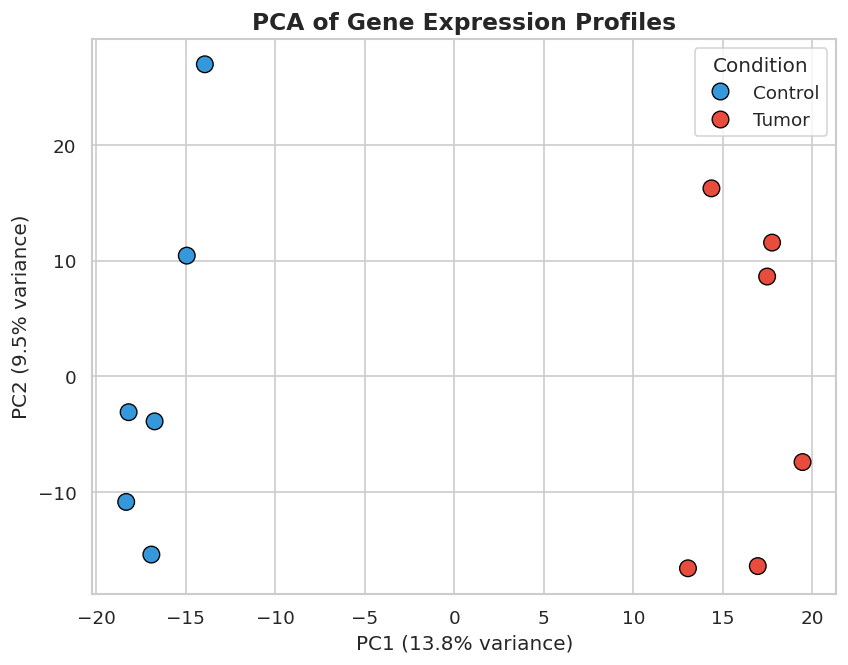

In [3]:
# Log2 transformation (with pseudocount of 1 to handle zeros)
log_counts = np.log2(count_matrix + 1)

# Transpose for PCA (samples as rows, genes as columns)
pca_input = log_counts.T
scaler = StandardScaler()
scaled_data = scaler.fit_transform(pca_input)

pca = PCA(n_components=2)
pca_coords = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(pca_coords, index=pca_input.index, columns=['PC1', 'PC2'])
pca_df['Condition'] = metadata['Condition']

# Plot PCA
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_df, x='PC1', y='PC2', hue='Condition',
    palette=['#3498db', '#e74c3c'], s=100, edgecolor='black'
)
plt.title('PCA of Gene Expression Profiles', fontsize=14, fontweight='bold')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.legend(title='Condition')
plt.show()

In [4]:
control_cols = metadata[metadata['Condition'] == 'Control'].index
tumor_cols = metadata[metadata['Condition'] == 'Tumor'].index

results = []

for gene in count_matrix.index:
    ctrl_vals = log_counts.loc[gene, control_cols]
    tum_vals = log_counts.loc[gene, tumor_cols]

    # Calculate Mean expression and Log2 Fold Change
    mean_ctrl = ctrl_vals.mean()
    mean_tum = tum_vals.mean()
    log2_fc = mean_tum - mean_ctrl

    # Independent t-test
    t_stat, p_val = stats.ttest_ind(tum_vals, ctrl_vals)
    results.append({'Gene': gene, 'Log2FC': log2_fc, 'p_value': p_val})

deg_results = pd.DataFrame(results).set_index('Gene')

# Multiple testing correction (Benjamini-Hochberg FDR)
_, adj_pvals, _, _ = multipletests(deg_results['p_value'], method='fdr_bh')
deg_results['padj'] = adj_pvals

# Sort by statistical significance
deg_results = deg_results.sort_values('padj')
print("Top 5 Differentially Expressed Genes:")
print(deg_results.head())

Top 5 Differentially Expressed Genes:
             Log2FC       p_value          padj
Gene                                           
GENE_0038  2.150190  1.838089e-09  9.190446e-07
GENE_0058  1.957382  8.775237e-10  9.190446e-07
GENE_0020  1.898237  1.762233e-09  9.190446e-07
GENE_0031  2.172286  1.099789e-09  9.190446e-07
GENE_0025  1.880177  2.833194e-09  1.133278e-06


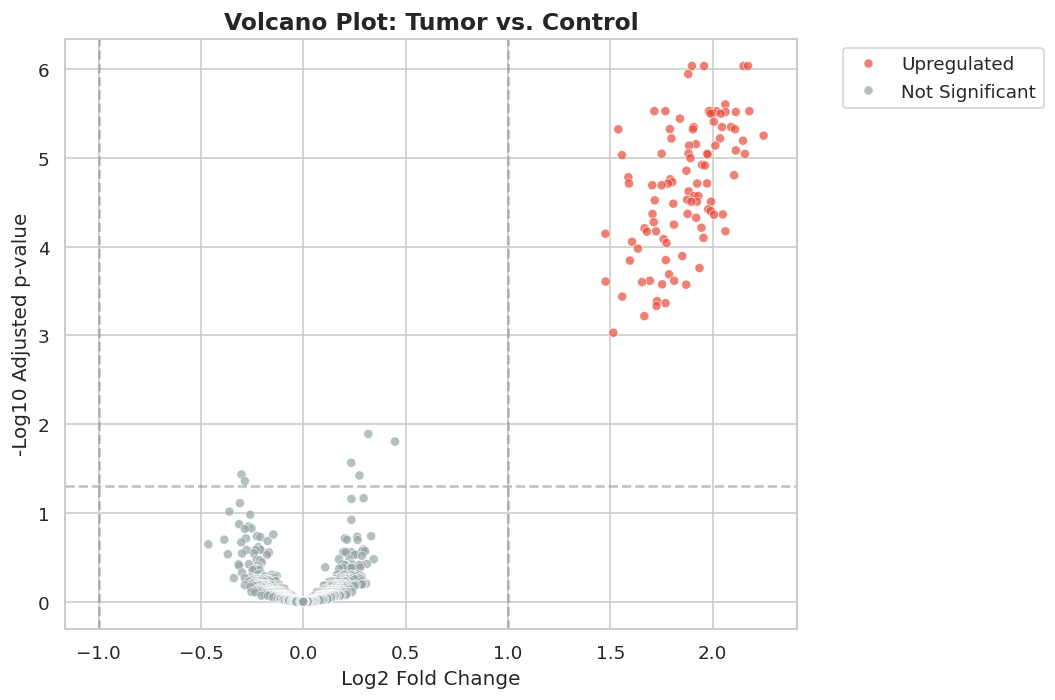

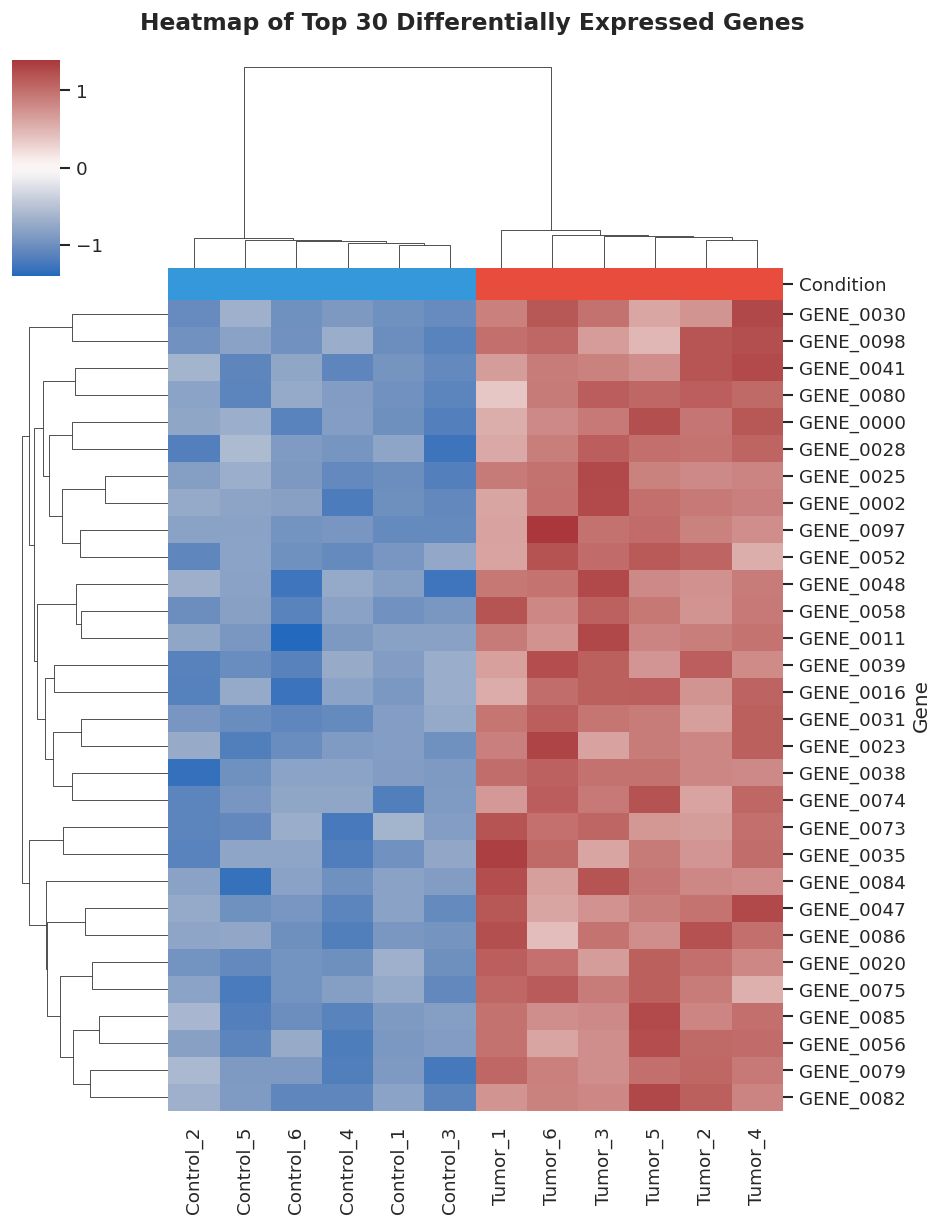

In [5]:
# 1. Volcano Plot
plt.figure(figsize=(9, 6))
deg_results['Significance'] = 'Not Significant'
deg_results.loc[(deg_results['padj'] < 0.05) & (deg_results['Log2FC'] > 1), 'Significance'] = 'Upregulated'
deg_results.loc[(deg_results['padj'] < 0.05) & (deg_results['Log2FC'] < -1), 'Significance'] = 'Downregulated'

sns.scatterplot(
    data=deg_results, x='Log2FC', y=-np.log10(deg_results['padj']),
    hue='Significance', palette={'Upregulated': '#e74c3c', 'Downregulated': '#3498db', 'Not Significant': '#95a5a6'},
    alpha=0.7, s=30
)

plt.axvline(x=1, color='grey', linestyle='--', alpha=0.5)
plt.axvline(x=-1, color='grey', linestyle='--', alpha=0.5)
plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', alpha=0.5)

plt.title('Volcano Plot: Tumor vs. Control', fontsize=14, fontweight='bold')
plt.xlabel('Log2 Fold Change')
plt.ylabel('-Log10 Adjusted p-value')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 2. Clustered Heatmap of Top 30 Significant Genes
top_genes = deg_results.head(30).index
heatmap_data = log_counts.loc[top_genes]

g = sns.clustermap(
    heatmap_data, z_score=0, cmap='vlag',
    figsize=(8, 10), col_colors=metadata['Condition'].map({'Control': '#3498db', 'Tumor': '#e74c3c'})
)
g.fig.suptitle('Heatmap of Top 30 Differentially Expressed Genes', y=1.02, fontsize=14, fontweight='bold')
plt.show()